***step 1: Identify the random variable***

1. What does (X=1) represent?
   * X=1 represent the customer clicks the link

2. What does (X=0) represent?
   * X=0 represents that the cusdtomer does not click the link

3. What are the possible values of (X)?
   * X --> 1,0

4. Is (X) discrete or continuous?
   * discrete random variable

5. Which probability distribution is suitable?
   * burnolli distribution


In [4]:
p = 0.30
sample_size = 20

***Step 2: Write the theoretical PMF***

For a Bernoulli random variable:
    P(X=x)=px(1−p)1−x

Here:

p=0.30

Probability of click
    P(X = 1) = 0.30^1 * (1 - 0.30)^(1 - 1) 
    P(X=1)=0.30

Probability of no click
    P(X=0)=1−0.30
    P(X=0)=0.70

Check:

0.70 + 0.30 = 1 

So the PMF is valid.

In [8]:
theoretical_pmf = {
    0: 1 - p,
    1: p
}

print("THEORETICAL PMF")
print("-" * 40)
print(f"P(X = 0) = {theoretical_pmf[0]:.2f}")
print(f"P(X = 1) = {theoretical_pmf[1]:.2f}")


THEORETICAL PMF
----------------------------------------
P(X = 0) = 0.70
P(X = 1) = 0.30


***Step 3 — Generate Outcomes for 20 Customers***

In [11]:
np.random.seed(42)

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from math import comb

samples = np.random.binomial(
    n=1,
    p=p,
    size=sample_size
)

In [13]:
print("\nGENERATED OBSERVATIONS")
print("-" * 40)
print(samples)
print("Number of observations:", len(samples))


GENERATED OBSERVATIONS
----------------------------------------
[0 1 1 0 0 0 0 1 0 1 0 1 1 0 0 0 0 0 0 0]
Number of observations: 20


1.	How many observations were generated? 
    * 20

2.	What does each zero represent? 
    * customer who does not click

3.	What does each one represent? 
    * customer clicked

4.	Are your generated observations the same as the theoretical probabilities?
    * in this case YES but 
    * Not necessarily. The theoretical probabilities are:

    P(X=0)=0.70  P(X=1)=0.30 

    The generated sample is random, so its proportions may be different from 0.70 and 0.30. With a particular random seed, you get one specific sample.

***Step 4: Count clicks and non-clicks***

In [14]:
number_of_clicks = np.sum(samples == 1)

In [15]:
number_of_non_clicks = np.sum(samples == 0)

In [18]:
print(f"number_of_clicks = {number_of_clicks}")
print(f"number_of_clicks = {number_of_non_clicks}")

number_of_clicks = 6
number_of_clicks = 14


1.	How many customers clicked? 
    * 6

2.	How many customers did not click?
    * 14

3.	Do the two counts add up to 20?
    * yes

***Step 5 — Empirical PMF***

In [ ]:
P^(X=1)=number of clicks / total observations

P^(X=1)=6 / 20

P^(X=1)=0.30

​P^(X=0)= 0.70

In [30]:
print("STEP 5: EMPIRICAL PMF")
print("=" * 60)

empirical_P_X_0 = number_of_non_clicks / sample_size
empirical_P_X_1 = number_of_clicks / sample_size

print(f"Empirical P(X = 0): {empirical_P_X_0:.2f}")
print(f"Empirical P(X = 1): {empirical_P_X_1:.2f}")

print(f"Sum of empirical probabilities: "
      f"{empirical_P_X_0 + empirical_P_X_1:.2f}")

STEP 5: EMPIRICAL PMF
Empirical P(X = 0): 0.70
Empirical P(X = 1): 0.30
Sum of empirical probabilities: 1.00


***Step 6: Compare empirical and theoretical PMFs***

Outcome         Theoretical         Empirical
X=0         	    0.70	          0.70
X=1	                0.30	          0.30

1. Is the empirical probability of a click exactly 0.30? 
        * NO

2. Which outcome has the larger probability? 
        * X=0

3. Why are the empirical and theoretical probabilities different?
        Because the theoretical probability is the population/model probability,
         while the empirical probability is calculated from a finite random sample.

In [31]:
print("\nPMF COMPARISON")
print("-" * 40)

for x in [0, 1]:

    difference = abs(
        theoretical_pmf[x] - empirical_pmf[x]
    )

    print(
        f"X = {x}: "
        f"Theoretical = {theoretical_pmf[x]:.2f}, "
        f"Empirical = {empirical_pmf[x]:.2f}, "
        f"Difference = {difference:.2f}"
    )



PMF COMPARISON
----------------------------------------
X = 0: Theoretical = 0.70, Empirical = 0.70, Difference = 0.00
X = 1: Theoretical = 0.30, Empirical = 0.30, Difference = 0.00


***Step 7: Plot empirical and theoretical PMFs***

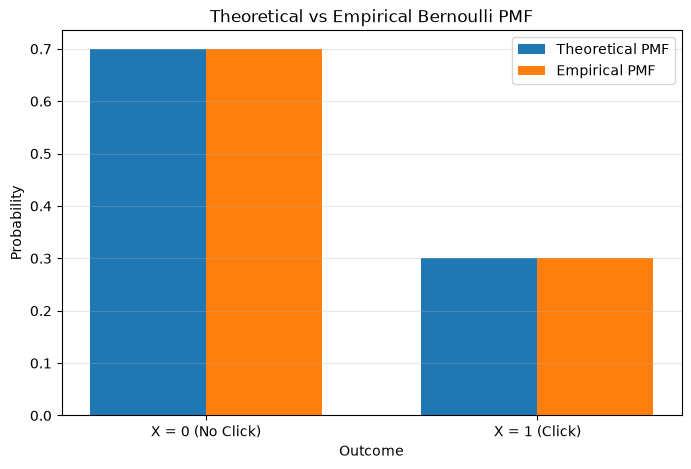

In [32]:
x = np.array([0, 1])

theoretical_values = np.array([
    theoretical_pmf[0],
    theoretical_pmf[1]
])

empirical_values = np.array([
    empirical_pmf[0],
    empirical_pmf[1]
])

width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    x - width / 2,
    theoretical_values,
    width,
    label="Theoretical PMF"
)

plt.bar(
    x + width / 2,
    empirical_values,
    width,
    label="Empirical PMF"
)

plt.xlabel("Outcome")
plt.ylabel("Probability")

plt.xticks(
    x,
    ["X = 0 (No Click)", "X = 1 (Click)"]
)

plt.title(
    "Theoretical vs Empirical Bernoulli PMF"
)

plt.legend()

plt.grid(
    axis="y",
    alpha=0.3
)

plt.show()


***Step 8: Calculate the theoretical expectation***

In [33]:
print("STEP 8: THEORETICAL EXPECTATION")
print("=" * 60)

theoretical_expectation = p

print(f"Theoretical expectation E[X] = "
      f"{theoretical_expectation:.2f}")

STEP 8: THEORETICAL EXPECTATION
Theoretical expectation E[X] = 0.30


***Step 9 — Calculate Empirical Expectation***

In [34]:
print("STEP 9: EMPIRICAL EXPECTATION")
print("=" * 60)

empirical_expectation = np.mean(samples)

print(f"Empirical expectation = "
      f"{empirical_expectation:.2f}")

STEP 9: EMPIRICAL EXPECTATION
Empirical expectation = 0.30


***Step 10 — Calculate Theoretical Variance***

In [35]:
print("STEP 10: THEORETICAL VARIANCE")
print("=" * 60)

theoretical_variance = p * (1 - p)

print(f"Theoretical variance = "
      f"{theoretical_variance:.2f}")

STEP 10: THEORETICAL VARIANCE
Theoretical variance = 0.21


***Step 11 — Calculate Empirical Variance***

In [36]:
print("STEP 11: EMPIRICAL VARIANCE")
print("=" * 60)

empirical_variance = np.var(samples)

print(f"Empirical variance = "
      f"{empirical_variance:.2f}")

STEP 11: EMPIRICAL VARIANCE
Empirical variance = 0.21
